# 02_08 Student's t, Chi-square and F

**Learning objectives**
- Understand **sampling distributions**: the distributions of quantities *computed from a sample* (a mean, a variance, a ratio of variances), not of single observations.
- Define the **chi-square**, **Student's t** and **F** distributions from the Normal, and see how they relate to each other.
- Derive the key facts (mean and variance of $\chi^2$, why the t has heavier tails, the link $t^2\sim F$) and read tables and quantiles.
- Solve three problems (small-sample quality test, test for a variance, comparing two variances) by hand, in code and by simulation.

**Prerequisites:** [02_01 Uniform and Normal](02_01_uniform_normal.ipynb) (z-scores, standard normal), [02_03 Exponential, Gamma and Erlang](02_03_exponential_gamma_erlang.ipynb) (the Gamma family, since $\chi^2$ is a Gamma).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Normal data:** if $X_1,\dots,X_n$ are independent $N(\mu,\sigma^2)$, the sample mean $\bar X=\frac1n\sum X_i$ is $N(\mu,\sigma^2/n)$. So $Z=\dfrac{\bar X-\mu}{\sigma/\sqrt n}\sim N(0,1)$ when $\sigma$ is known.
- **Sample variance:** $s^2=\dfrac1{n-1}\sum(X_i-\bar X)^2$ (divide by $n-1$, which makes it unbiased).
- **Standard error:** $\mathrm{SE}=s/\sqrt n$, the estimated SD of $\bar X$.
- **Gamma distribution** (02_03): shape $k$, scale $\theta$; the **chi-square** is the special case $k=\nu/2$, $\theta=2$.
- **Critical value / quantile:** the point with a given tail area; the 97.5th percentile of the standard normal is 1.96.

## 3. Intuition and story

### 3.1 The problem: we do not know $\sigma$
A z-interval $\bar x\pm1.96\,\sigma/\sqrt n$ needs the true SD $\sigma$. In practice we only have the sample SD $s$. For large $n$ replacing $\sigma$ by $s$ is harmless, but for **small samples** $s$ is itself noisy, and it can be too small by chance, making the interval too narrow and the test too eager. In 1908 William Gosset ("Student", a brewer at Guinness) worked out the exact distribution of
$$T=\frac{\bar X-\mu}{s/\sqrt n},$$
the **Student's t distribution**. It has the same bell shape as the Normal but **heavier tails**, to account for the extra uncertainty from estimating $\sigma$.

### 3.2 Three distributions built from the Normal
- **Chi-square $\chi^2_k$:** the sum of the squares of $k$ independent standard normals. It describes quantities like $(n-1)s^2/\sigma^2$: how the sample variance fluctuates.
- **Student's t$_\nu$:** a standard normal divided by $\sqrt{\chi^2_\nu/\nu}$: a Normal whose scale is uncertain.
- **F$_{d_1,d_2}$:** a ratio of two independent chi-squares each divided by its degrees of freedom: how a *ratio of two sample variances* fluctuates.

The picture below shows the idea for the t: with only 5 observations, the standardized mean $T$ lands in the tails more often than a Normal says.

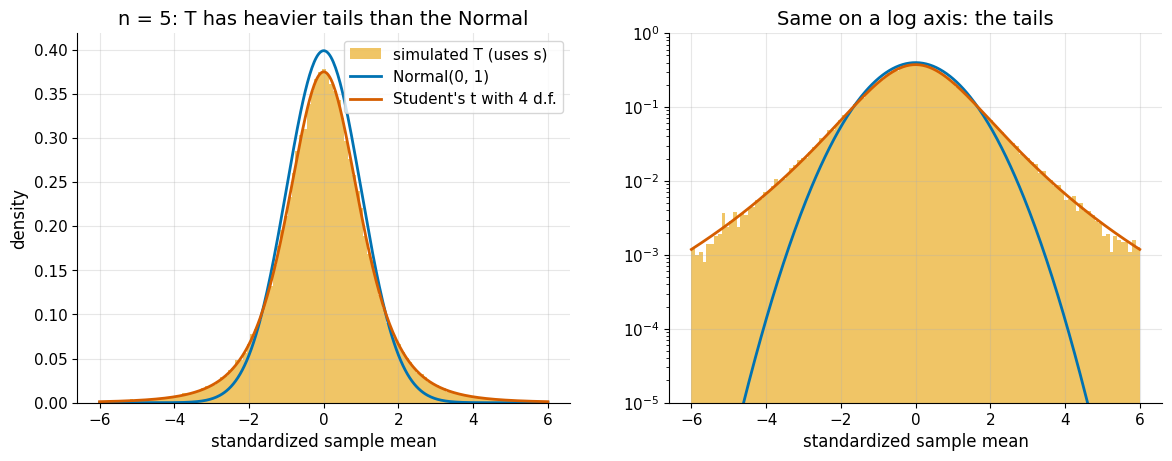

P(|T| > 1.96) = 0.1231   P(|Z| > 1.96) = 0.0499


In [2]:
n = 5
n_experiments = 100_000
data = rng.normal(loc=50, scale=10, size=(n_experiments, n))
sample_means = data.mean(axis=1)
sample_sds = data.std(axis=1, ddof=1)
t_statistics = (sample_means - 50) / (sample_sds / np.sqrt(n))      # uses the sample SD
z_statistics = (sample_means - 50) / (10 / np.sqrt(n))              # uses the true SD

grid = np.linspace(-6, 6, 400)
fig, (ax_lin, ax_log) = plt.subplots(1, 2, figsize=(14, 4.8))
for ax in (ax_lin, ax_log):
    ax.hist(t_statistics, bins=np.linspace(-6, 6, 120), density=True, color=SIM, alpha=0.6, label="simulated T (uses s)")
    ax.plot(grid, stats.norm.pdf(grid), color=COLORS[0], linewidth=2, label="Normal(0, 1)")
    ax.plot(grid, stats.t(df=n - 1).pdf(grid), color=HIGHLIGHT, linewidth=2, label="Student's t with 4 d.f.")
    ax.set_xlabel("standardized sample mean")
ax_lin.set_ylabel("density")
ax_lin.set_title("n = 5: T has heavier tails than the Normal")
ax_log.set_yscale("log")
ax_log.set_ylim(1e-5, 1)
ax_log.set_title("Same on a log axis: the tails")
ax_lin.legend()
plt.show()
print("P(|T| > 1.96) =", round(np.mean(np.abs(t_statistics) > 1.96), 4), "  P(|Z| > 1.96) =", round(np.mean(np.abs(z_statistics) > 1.96), 4))

**In plain words.** If you standardize with the *estimated* SD from only 5 values, you land beyond $\pm1.96$ about 12 % of the time, not 5 %. The t distribution fixes the bookkeeping: its quantile for 95 % with 4 degrees of freedom is 2.78 instead of 1.96.

## 4. Formal definition

**Chi-square($\nu$):** support $x\ge0$; degrees of freedom $\nu>0$. $\chi^2_\nu=Z_1^2+\dots+Z_\nu^2$ for iid standard normals; equivalently Gamma($\nu/2$, scale 2):
$$f(x)=\frac{x^{\nu/2-1}e^{-x/2}}{2^{\nu/2}\Gamma(\nu/2)}.$$

**Student's t($\nu$):** support $\mathbb R$; $T=\dfrac Z{\sqrt{V/\nu}}$ with $Z\sim N(0,1)$ and $V\sim\chi^2_\nu$ independent:
$$f(x)=\frac{\Gamma\big(\frac{\nu+1}2\big)}{\sqrt{\nu\pi}\,\Gamma\big(\frac\nu2\big)}\Big(1+\frac{x^2}\nu\Big)^{-(\nu+1)/2}.$$

**F($d_1,d_2$):** support $x\ge0$; $F=\dfrac{U/d_1}{V/d_2}$ with $U\sim\chi^2_{d_1}$, $V\sim\chi^2_{d_2}$ independent.

**`scipy`:** `stats.chi2(df)`, `stats.t(df)` (add `loc`, `scale` if needed), `stats.f(dfn, dfd)`.

## 5. Derivations

### 5.1 Chi-square with 1 degree of freedom
Let $Y=Z^2$. For $y>0$: $F_Y(y)=P(-\sqrt y\le Z\le\sqrt y)=2\Phi(\sqrt y)-1$. Differentiating, with $\frac d{dy}\sqrt y=\frac1{2\sqrt y}$:
$$f_Y(y)=2\varphi(\sqrt y)\frac1{2\sqrt y}=\frac{1}{\sqrt{2\pi y}}e^{-y/2}.$$
This is the Gamma($\tfrac12$, scale 2) density, confirming $\chi^2_1$ is a Gamma.

### 5.2 Mean and variance of $\chi^2_\nu$
$E[Z^2]=1$ and $E[Z^4]=3$, so $\mathrm{Var}(Z^2)=3-1=2$. A sum of $\nu$ independent copies:
$$E[\chi^2_\nu]=\nu,\qquad\mathrm{Var}(\chi^2_\nu)=2\nu.$$
Also, the sum of independent $\chi^2_a$ and $\chi^2_b$ is $\chi^2_{a+b}$ (add the squares). Skewness is $\sqrt{8/\nu}$; for large $\nu$ the $\chi^2$ is approximately Normal$(\nu,2\nu)$.

### 5.3 Why the sample variance gives $\chi^2_{n-1}$
For Normal data, $\sum_i(X_i-\mu)^2/\sigma^2\sim\chi^2_n$. Replacing $\mu$ by $\bar X$ removes one degree of freedom because the deviations $X_i-\bar X$ must sum to 0, so only $n-1$ of them are free:
$$\frac{(n-1)s^2}{\sigma^2}\sim\chi^2_{n-1},$$
and, for Normal data, $\bar X$ and $s^2$ are **independent**. This independence is what makes the t statistic work.

### 5.4 The t statistic
$$T=\frac{\bar X-\mu}{s/\sqrt n}=\frac{(\bar X-\mu)/(\sigma/\sqrt n)}{\sqrt{\frac{(n-1)s^2/\sigma^2}{n-1}}}=\frac{Z}{\sqrt{V/(n-1)}},\qquad Z\sim N(0,1),\ V\sim\chi^2_{n-1}\text{ independent},$$
so $T\sim t_{n-1}$ exactly. The denominator $\sqrt{V/(n-1)}$ fluctuates around 1; when it is small by chance $T$ is large, which creates the heavy tails.

### 5.5 Moments of the t
The mean is 0 for $\nu>1$ (it does not exist for $\nu=1$). The variance is $\dfrac\nu{\nu-2}$ for $\nu>2$ (infinite for $\nu\le2$), always above 1: the t is wider than the Normal. As $\nu\to\infty$, $V/\nu\to1$ and $T\to Z$: **the t converges to the standard Normal**. For $\nu=1$ the t is the **Cauchy** distribution (02_06).

### 5.6 The F distribution
$F=\dfrac{U/d_1}{V/d_2}$. Its mean is $\dfrac{d_2}{d_2-2}$ for $d_2>2$ (close to 1), and if $F\sim F_{d_1,d_2}$ then $1/F\sim F_{d_2,d_1}$. The ratio of two sample variances from Normal populations with equal variances is $F_{n_1-1,\,n_2-1}$.

### 5.7 How the three are linked
- $Z^2\sim\chi^2_1$.
- $T\sim t_\nu\Rightarrow T^2\sim F_{1,\nu}$ (square of a standard normal over an independent $\chi^2_\nu/\nu$).
- $\chi^2_\nu/\nu\to1$ as $\nu\to\infty$, so $t_\nu\to N(0,1)$ and $F_{d,\infty}=\chi^2_d/d$.
- $\chi^2_\nu=\text{Gamma}(\nu/2,\,\text{scale }2)$.

## 6. Properties and relationships

| Distribution | Built from | Used for | Mean | Variance |
|---|---|---|---|---|
| $\chi^2_\nu$ | sum of $\nu$ squared standard normals | variance tests, goodness of fit, independence tests | $\nu$ | $2\nu$ |
| $t_\nu$ | $Z/\sqrt{\chi^2_\nu/\nu}$ | mean tests and intervals with unknown $\sigma$ | 0 ($\nu>1$) | $\nu/(\nu-2)$ ($\nu>2$) |
| $F_{d_1,d_2}$ | $(\chi^2_{d_1}/d_1)/(\chi^2_{d_2}/d_2)$ | comparing variances, ANOVA, regression F-test | $d_2/(d_2-2)$ ($d_2>2$) | long formula |

These families are central in classical inference (Module 06). They are exact for **Normal data**; for other data they are good approximations when $n$ is large (Central Limit Theorem).

## 7. 2D visuals

### 7.1 Chi-square for several degrees of freedom
For 1 or 2 degrees of freedom the density is highest at 0; for more it develops a peak at nu - 2 and moves right with mean nu. For large nu it approaches a Normal.

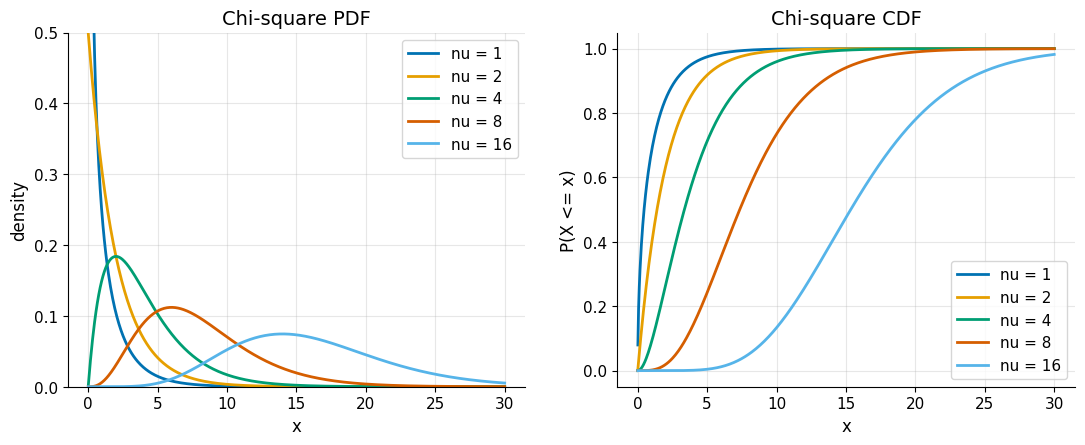

In [3]:
x_axis = np.linspace(0.01, 30, 600)
fig, (ax_pdf, ax_cdf) = plt.subplots(1, 2, figsize=(13, 4.6))
for df_value, color in zip([1, 2, 4, 8, 16], COLORS + ["black"]):
    d = stats.chi2(df=df_value)
    ax_pdf.plot(x_axis, d.pdf(x_axis), color=color, linewidth=2, label=f"nu = {df_value}")
    ax_cdf.plot(x_axis, d.cdf(x_axis), color=color, linewidth=2, label=f"nu = {df_value}")
ax_pdf.set_ylim(0, 0.5)
ax_pdf.set_title("Chi-square PDF")
ax_pdf.set_xlabel("x")
ax_pdf.set_ylabel("density")
ax_pdf.legend()
ax_cdf.set_title("Chi-square CDF")
ax_cdf.set_xlabel("x")
ax_cdf.set_ylabel("P(X <= x)")
ax_cdf.legend()
plt.show()

### 7.2 Student's t versus the Normal
The t is bell shaped and symmetric but lower in the middle and heavier in the tails. With 30 degrees of freedom it is already nearly Normal.

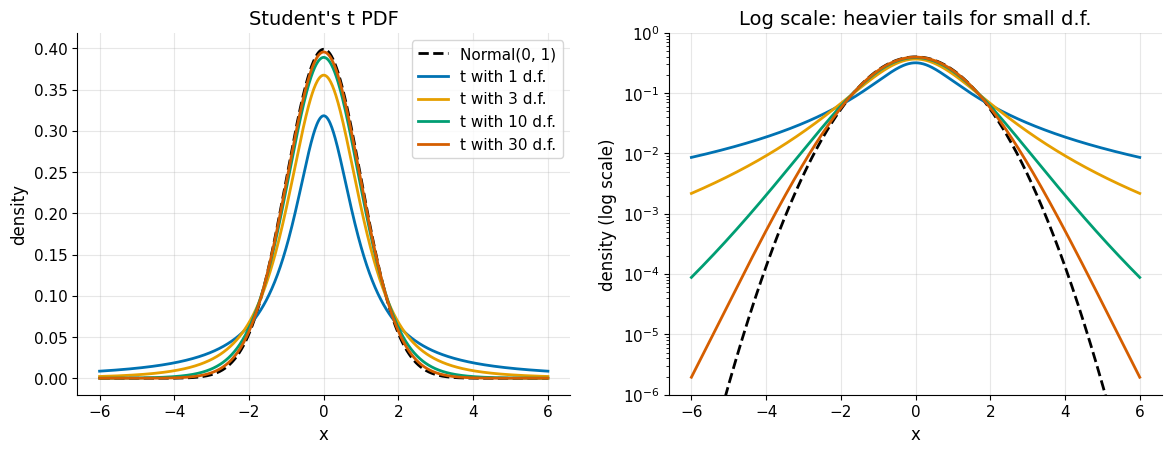

In [4]:
x_axis = np.linspace(-6, 6, 800)
fig, (ax_pdf, ax_tail) = plt.subplots(1, 2, figsize=(14, 4.7))
ax_pdf.plot(x_axis, stats.norm.pdf(x_axis), "--", color="black", linewidth=2, label="Normal(0, 1)")
ax_tail.semilogy(x_axis, stats.norm.pdf(x_axis), "--", color="black", linewidth=2, label="Normal(0, 1)")
for df_value, color in zip([1, 3, 10, 30], COLORS):
    d = stats.t(df=df_value)
    ax_pdf.plot(x_axis, d.pdf(x_axis), color=color, linewidth=2, label=f"t with {df_value} d.f.")
    ax_tail.semilogy(x_axis, d.pdf(x_axis), color=color, linewidth=2, label=f"t with {df_value} d.f.")
ax_pdf.set_title("Student's t PDF")
ax_pdf.set_xlabel("x")
ax_pdf.set_ylabel("density")
ax_pdf.legend()
ax_tail.set_ylim(1e-6, 1)
ax_tail.set_title("Log scale: heavier tails for small d.f.")
ax_tail.set_xlabel("x")
ax_tail.set_ylabel("density (log scale)")
plt.show()

### 7.3 How critical values converge
The 97.5th percentile of the t (the multiplier of a 95 % interval) decreases toward the Normal's 1.96 as the degrees of freedom grow. With few observations the multiplier is much larger.

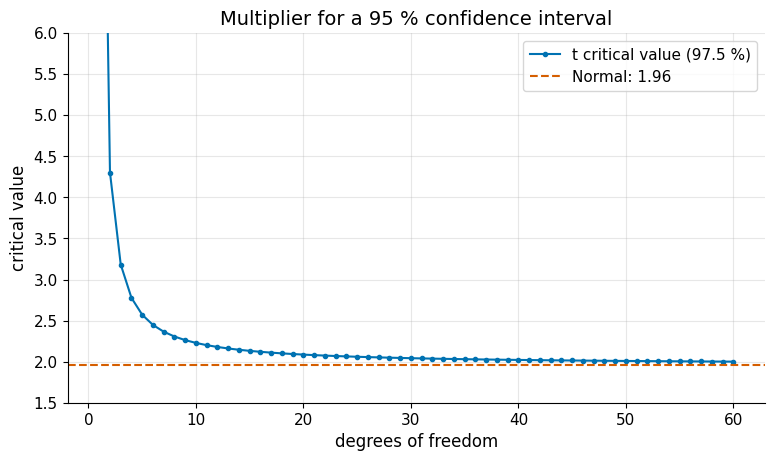

 d.f.  t 97.5 %
    2     4.303
    4     2.776
    7     2.365
   10     2.228
   20     2.086
   30     2.042
  100     1.984


In [5]:
df_axis = np.arange(1, 61)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(df_axis, stats.t.ppf(0.975, df_axis), "o-", markersize=3, color=MAIN, label="t critical value (97.5 %)")
ax.axhline(stats.norm.ppf(0.975), color=HIGHLIGHT, linestyle="--", label="Normal: 1.96")
ax.set_ylim(1.5, 6)
ax.set_title("Multiplier for a 95 % confidence interval")
ax.set_xlabel("degrees of freedom")
ax.set_ylabel("critical value")
ax.legend()
plt.show()
table = pd.DataFrame({"d.f.": [2, 4, 7, 10, 20, 30, 100]})
table["t 97.5 %"] = [round(stats.t.ppf(0.975, d), 3) for d in table["d.f."]]
print(table.to_string(index=False))

### 7.4 The F distribution
The F is right skewed, with mean close to 1. More degrees of freedom concentrate it near 1 (the two variances estimate the same thing with small error).

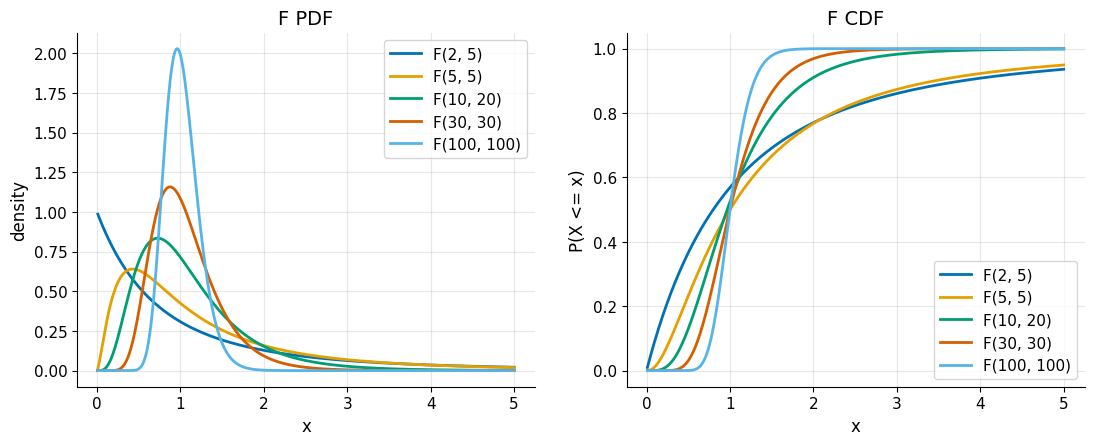

In [6]:
x_axis = np.linspace(0.01, 5, 600)
fig, (ax_pdf, ax_cdf) = plt.subplots(1, 2, figsize=(13, 4.6))
for (d1, d2), color in zip([(2, 5), (5, 5), (10, 20), (30, 30), (100, 100)], COLORS + ["black"]):
    d = stats.f(d1, d2)
    ax_pdf.plot(x_axis, d.pdf(x_axis), color=color, linewidth=2, label=f"F({d1}, {d2})")
    ax_cdf.plot(x_axis, d.cdf(x_axis), color=color, linewidth=2, label=f"F({d1}, {d2})")
ax_pdf.set_title("F PDF")
ax_pdf.set_xlabel("x")
ax_pdf.set_ylabel("density")
ax_pdf.legend()
ax_cdf.set_title("F CDF")
ax_cdf.set_xlabel("x")
ax_cdf.set_ylabel("P(X <= x)")
ax_cdf.legend()
plt.show()

### 7.5 The relationships, numerically
A quick tour of section 5.7: z squared is chi-square(1), t squared is F(1, nu), t with a huge nu is Normal.

In [7]:
p = 0.95
print(f"chi-square(1) 95 % quantile = {stats.chi2.ppf(p, 1):.4f}  vs  (z 97.5 %)^2 = {stats.norm.ppf(0.975) ** 2:.4f}")
print(f"F(1, 7) 95 % quantile = {stats.f.ppf(p, 1, 7):.4f}  vs  (t_7 97.5 %)^2 = {stats.t.ppf(0.975, 7) ** 2:.4f}")
print(f"t with 100000 d.f. 97.5 % quantile = {stats.t.ppf(0.975, 100_000):.4f}  vs  Normal {stats.norm.ppf(0.975):.4f}")
print(f"F(5, infinity) 95 % quantile x 5 = {stats.f.ppf(p, 5, 10_000_000) * 5:.4f}  vs  chi-square(5) 95 % quantile = {stats.chi2.ppf(p, 5):.4f}")

chi-square(1) 95 % quantile = 3.8415  vs  (z 97.5 %)^2 = 3.8415
F(1, 7) 95 % quantile = 5.5914  vs  (t_7 97.5 %)^2 = 5.5914
t with 100000 d.f. 97.5 % quantile = 1.9600  vs  Normal 1.9600
F(5, infinity) 95 % quantile x 5 = 11.0705  vs  chi-square(5) 95 % quantile = 11.0705


## 8. 3D visuals

### 8.1 Static: Student's t PDF over (x, nu)
As nu grows the low, heavy-tailed bell becomes the Normal bell.

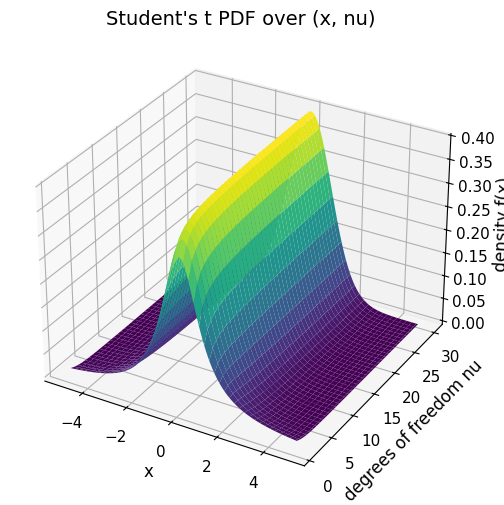

In [8]:
x_values = np.linspace(-5, 5, 140)
nu_values = np.linspace(1, 30, 40)
X, N = np.meshgrid(x_values, nu_values)
Z = stats.t.pdf(X, df=N)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, N, Z, cmap="viridis", edgecolor="none")
ax.set_title("Student's t PDF over (x, nu)")
ax.set_xlabel("x")
ax.set_ylabel("degrees of freedom nu")
ax.set_zlabel("density f(x)")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.2 Static: chi-square PDF over (x, nu)
The ridge moves right (mean nu) and flattens as nu grows.

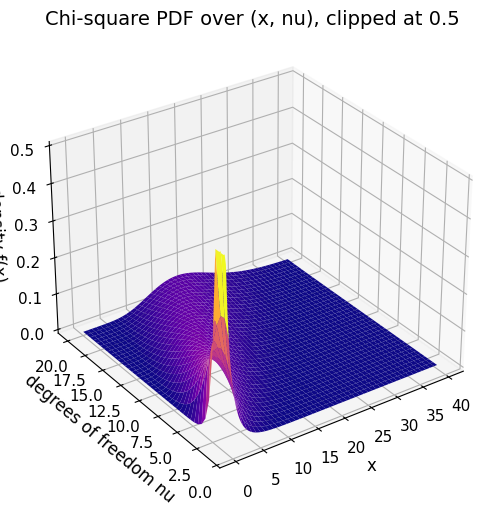

In [9]:
x_values2 = np.linspace(0.05, 40, 200)
nu_values2 = np.linspace(1, 20, 40)
X2, N2 = np.meshgrid(x_values2, nu_values2)
Z2 = stats.chi2.pdf(X2, df=N2)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X2, N2, np.minimum(Z2, 0.5), cmap="plasma", edgecolor="none")
ax.set_title("Chi-square PDF over (x, nu), clipped at 0.5")
ax.set_xlabel("x")
ax.set_ylabel("degrees of freedom nu")
ax.set_zlabel("density f(x)")
ax.view_init(elev=30, azim=-125)
plt.show()

### 8.3 Static: F PDF over (x, d2), d1 = 5
With few denominator degrees of freedom the F has a long right tail; with many it tightens around 1.

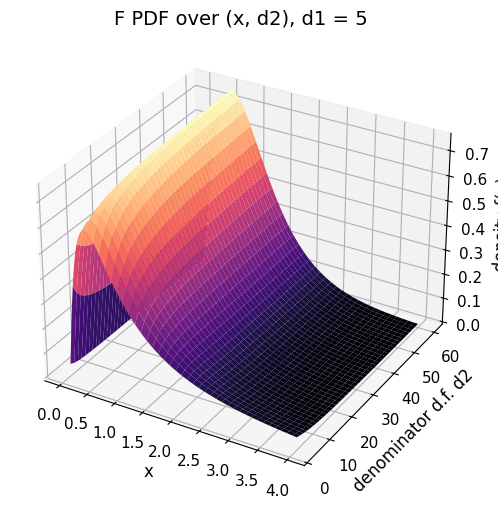

In [10]:
x_values3 = np.linspace(0.02, 4, 160)
d2_values = np.linspace(3, 60, 40)
X3, D3 = np.meshgrid(x_values3, d2_values)
Z3 = stats.f.pdf(X3, 5, D3)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X3, D3, Z3, cmap="magma", edgecolor="none")
ax.set_title("F PDF over (x, d2), d1 = 5")
ax.set_xlabel("x")
ax.set_ylabel("denominator d.f. d2")
ax.set_zlabel("density f(x)")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.4 Interactive Plotly version
The t surface of 8.1; drag to rotate.

In [11]:
fig = go.Figure(go.Surface(x=x_values, y=nu_values, z=Z, colorscale="Viridis"))
fig.update_layout(title="Student's t PDF over (x, nu)", width=750, height=550,
                  scene=dict(xaxis_title="x", yaxis_title="degrees of freedom nu", zaxis_title="density f(x)"))
fig.show()

## 9. Simulation vs theory

We draw many small Normal samples (n = 8 from N(50, 10^2)) and check each theoretical claim of section 5.

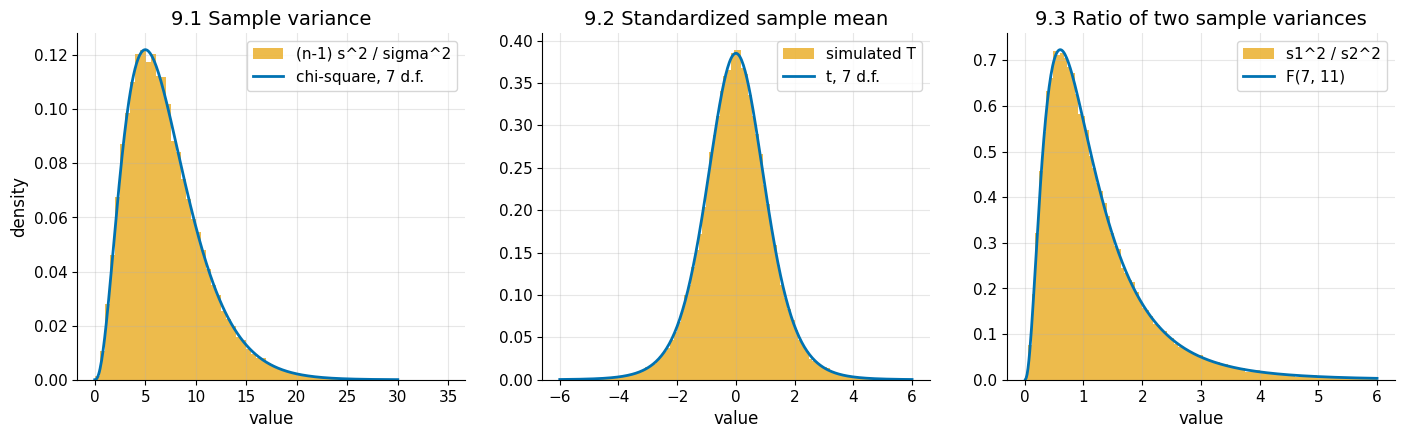

KS p-values (large = consistent): 0.457 0.281 0.589
independence of mean and variance: correlation = 0.0003


In [12]:
n, mu_true, sigma_true = 8, 50, 10
n_experiments = 100_000
data = rng.normal(mu_true, sigma_true, size=(n_experiments, n))
means = data.mean(axis=1)
variances = data.var(axis=1, ddof=1)
t_stat = (means - mu_true) / np.sqrt(variances / n)
chi_stat = (n - 1) * variances / sigma_true**2

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(chi_stat, bins=70, density=True, color=SIM, alpha=0.7, label="(n-1) s^2 / sigma^2")
grid = np.linspace(0, 30, 400)
axes[0].plot(grid, stats.chi2(n - 1).pdf(grid), color=MAIN, linewidth=2, label="chi-square, 7 d.f.")
axes[0].set_title("9.1 Sample variance")
axes[0].set_xlabel("value")
axes[0].set_ylabel("density")
axes[0].legend()

grid_t = np.linspace(-6, 6, 400)
axes[1].hist(t_stat, bins=np.linspace(-6, 6, 100), density=True, color=SIM, alpha=0.7, label="simulated T")
axes[1].plot(grid_t, stats.t(n - 1).pdf(grid_t), color=MAIN, linewidth=2, label="t, 7 d.f.")
axes[1].set_title("9.2 Standardized sample mean")
axes[1].set_xlabel("value")
axes[1].legend()

second = rng.normal(mu_true, sigma_true, size=(n_experiments, 12)).var(axis=1, ddof=1)
f_stat = variances / second
grid_f = np.linspace(0.01, 6, 400)
axes[2].hist(f_stat, bins=np.linspace(0, 6, 100), density=True, color=SIM, alpha=0.7, label="s1^2 / s2^2")
axes[2].plot(grid_f, stats.f(7, 11).pdf(grid_f), color=MAIN, linewidth=2, label="F(7, 11)")
axes[2].set_title("9.3 Ratio of two sample variances")
axes[2].set_xlabel("value")
axes[2].legend()
plt.show()
print("KS p-values (large = consistent):",
      round(stats.kstest(chi_stat, stats.chi2(n - 1).cdf).pvalue, 3), round(stats.kstest(t_stat, stats.t(n - 1).cdf).pvalue, 3), round(stats.kstest(f_stat, stats.f(7, 11).cdf).pvalue, 3))
print("independence of mean and variance: correlation =", round(np.corrcoef(means, variances)[0, 1], 4))

### 9.4 Coverage of confidence intervals with n = 5
We build 95 % intervals from many small samples, once with the Normal multiplier 1.96 and once with the t multiplier. Only the t interval covers the true mean 95 % of the time.

In [13]:
n = 5
data = rng.normal(mu_true, sigma_true, size=(200_000, n))
means = data.mean(axis=1)
standard_errors = data.std(axis=1, ddof=1) / np.sqrt(n)
z_multiplier = stats.norm.ppf(0.975)
t_multiplier = stats.t.ppf(0.975, n - 1)
coverage_z = np.mean(np.abs(means - mu_true) <= z_multiplier * standard_errors)
coverage_t = np.mean(np.abs(means - mu_true) <= t_multiplier * standard_errors)
print(f"n = 5: coverage with 1.96 = {coverage_z:.4f}; with the t multiplier {t_multiplier:.3f} = {coverage_t:.4f}")
assert abs(coverage_t - 0.95) < 0.003

n = 5: coverage with 1.96 = 0.8786; with the t multiplier 2.776 = 0.9496


## 10. `scipy.stats` cheat sheet

In [14]:
print("t(7):    cdf(1.587) =", round(stats.t(7).cdf(1.587), 4), " sf(1.587) =", round(stats.t(7).sf(1.587), 4), " ppf(0.975) =", round(stats.t(7).ppf(0.975), 4))
print("t(7):    mean, var =", stats.t(7).mean(), round(stats.t(7).var(), 4), "(= 7/5)")
print("chi2(19): sf(35.49) =", round(stats.chi2(19).sf(35.49), 4), " ppf(0.95) =", round(stats.chi2(19).ppf(0.95), 3), " mean, var =", stats.chi2(19).mean(), stats.chi2(19).var())
print("F(14, 11): sf(2.54) =", round(stats.f(14, 11).sf(2.54), 4), " ppf(0.95) =", round(stats.f(14, 11).ppf(0.95), 3))
print("chi2 interval(0.95):", np.round(stats.chi2(10).interval(0.95), 3))
print("rvs examples        :", stats.t(5).rvs(3, random_state=1).round(2), stats.chi2(5).rvs(3, random_state=1).round(2), stats.f(5, 10).rvs(3, random_state=1).round(2))

sample = rng.normal(10, 2, size=12)
t_result = stats.ttest_1samp(sample, popmean=9)                # ready-made one-sample t test
print("ttest_1samp:", round(t_result.statistic, 3), round(t_result.pvalue, 4))

t(7):    cdf(1.587) = 0.9217  sf(1.587) = 0.0783  ppf(0.975) = 2.3646
t(7):    mean, var = 0.0 1.4 (= 7/5)
chi2(19): sf(35.49) = 0.0122  ppf(0.95) = 30.144  mean, var = 19.0 38.0
F(14, 11): sf(2.54) = 0.0635  ppf(0.95) = 2.739
chi2 interval(0.95): [ 3.247 20.483]
rvs examples        : [ 2.18 -1.01 -0.86] [11.09  2.77  2.96] [3.2  1.09 3.67]
ttest_1samp: 2.455 0.0319


**Fitting:** the Student's t can be fit to data with `stats.t.fit` (it estimates df, location and scale), useful to describe heavy-tailed but symmetric data. The chi-square and F are mostly used as reference distributions for tests rather than fitted.

In [15]:
heavy = stats.t(df=4, loc=2, scale=3).rvs(size=5000, random_state=7)
df_hat, loc_hat, scale_hat = stats.t.fit(heavy)
print(f"true df = 4, loc = 2, scale = 3 -> fitted df = {df_hat:.2f}, loc = {loc_hat:.2f}, scale = {scale_hat:.2f}")

true df = 4, loc = 2, scale = 3 -> fitted df = 3.85, loc = 2.00, scale = 2.98


## 11. Real-world worked examples

---
### Example 1 (main): small-sample quality test (t)

**Scenario (illustrative numbers).** A cereal box is labelled **500 g**. A quality inspector weighs **8 boxes** and finds the weights (in grams)
$$498.2,\ 505.6,\ 503.1,\ 499.0,\ 507.4,\ 501.8,\ 496.5,\ 504.8.$$
The factory's true SD is unknown, so the t distribution is needed.

**Questions**
1. What are the sample mean, SD and standard error?
2. Give a **95 % confidence interval** for the true mean fill. How does it compare with a (wrong) z-interval?
3. **Test** whether the true mean differs from the label of 500 g (two-sided, 5 % level).

### 11.1 By hand
Sum $=498.2+505.6+503.1+499.0+507.4+501.8+496.5+504.8=4016.4$, so $\bar x=4016.4/8=502.05$ g.
Squared deviations: $(-3.85)^2=14.82,\ 3.55^2=12.60,\ 1.05^2=1.10,\ (-3.05)^2=9.30,\ 5.35^2=28.62,\ (-0.25)^2=0.06,\ (-5.55)^2=30.80,\ 2.75^2=7.56$; total $=104.87$.
$s^2=104.87/(8-1)=14.98$, $s=3.871$ g, $\mathrm{SE}=s/\sqrt8=3.871/2.828=1.369$ g.

**Q2.** With 7 degrees of freedom the table value is $t_{0.975,7}=2.365$. The interval is $502.05\pm2.365\times1.369=502.05\pm3.24=(498.81,\ 505.29)$. (The wrong z-interval would use 1.96: $502.05\pm2.68=(499.37,\ 504.73)$, too narrow.)

**Q3.** $H_0:\mu=500$. $T=\dfrac{502.05-500}{1.369}=1.498$. Since $|T|=1.498<2.365$ (the two-sided 5 % critical value) we **do not reject** $H_0$.

In [16]:
import math

weights = [498.2, 505.6, 503.1, 499.0, 507.4, 501.8, 496.5, 504.8]
n = len(weights)

mean_hand = sum(weights) / n
sum_squares = 0.0
for w in weights:
    sum_squares += (w - mean_hand) ** 2
sd_hand = math.sqrt(sum_squares / (n - 1))
se_hand = sd_hand / math.sqrt(n)

t_critical_table = 2.365                          # t with 7 d.f., 97.5 %, from a table
interval_hand = (mean_hand - t_critical_table * se_hand, mean_hand + t_critical_table * se_hand)
t_statistic_hand = (mean_hand - 500) / se_hand
print(f"mean = {mean_hand:.3f}, SD = {sd_hand:.3f}, SE = {se_hand:.3f}")
print(f"95% t interval = ({interval_hand[0]:.2f}, {interval_hand[1]:.2f}); T = {t_statistic_hand:.3f} (critical value {t_critical_table})")

mean = 502.050, SD = 3.871, SE = 1.369
95% t interval = (498.81, 505.29); T = 1.498 (critical value 2.365)


### 11.2 In code with `scipy`, and the asserts

In [17]:
weights_array = np.array(weights)
t_distribution = stats.t(df=n - 1)

assert np.isclose(mean_hand, weights_array.mean())
assert np.isclose(sd_hand, weights_array.std(ddof=1))
assert np.isclose(t_critical_table, t_distribution.ppf(0.975), atol=0.001)
interval_code = stats.t.interval(0.95, df=n - 1, loc=weights_array.mean(), scale=stats.sem(weights_array))
assert np.allclose(interval_hand, interval_code, atol=0.005)

p_value = 2 * t_distribution.sf(abs(t_statistic_hand))
test = stats.ttest_1samp(weights_array, popmean=500)             # the same test in one call
assert np.isclose(t_statistic_hand, test.statistic)
assert np.isclose(p_value, test.pvalue)
z_interval = (mean_hand - 1.96 * se_hand, mean_hand + 1.96 * se_hand)
print(f"t interval (498.8, 505.3) -> {np.round(interval_code, 2)}; z interval {np.round(z_interval, 2)} is too narrow")
print(f"T = {test.statistic:.3f}, two-sided p-value = {test.pvalue:.4f} -> do not reject at 5 %")

t interval (498.8, 505.3) -> [498.81 505.29]; z interval [499.37 504.73] is too narrow
T = 1.498, two-sided p-value = 0.1778 -> do not reject at 5 %


### 11.3 Verify by simulation
If the true mean really is 500, how often would a test on 8 boxes reject? And how often does the interval cover the true mean? We simulate 200,000 inspections with the same SD.

In [18]:
true_mean, true_sd = 500, sd_hand
inspections = rng.normal(true_mean, true_sd, size=(200_000, n))
sim_means = inspections.mean(axis=1)
sim_se = inspections.std(axis=1, ddof=1) / np.sqrt(n)
t_values = (sim_means - 500) / sim_se
reject_rate = np.mean(np.abs(t_values) > t_critical_table)
coverage = np.mean(np.abs(sim_means - true_mean) <= t_critical_table * sim_se)
z_reject_rate = np.mean(np.abs(t_values) > 1.96)
print(f"false-alarm rate with the t critical value 2.365: {reject_rate:.4f} (target 0.05)")
print(f"coverage of the t interval: {coverage:.4f} (target 0.95)")
print(f"false-alarm rate if 1.96 were wrongly used: {z_reject_rate:.4f}")
assert abs(reject_rate - 0.05) < 0.003

false-alarm rate with the t critical value 2.365: 0.0501 (target 0.05)
coverage of the t interval: 0.9499 (target 0.95)
false-alarm rate if 1.96 were wrongly used: 0.0908


### 11.4 Plots

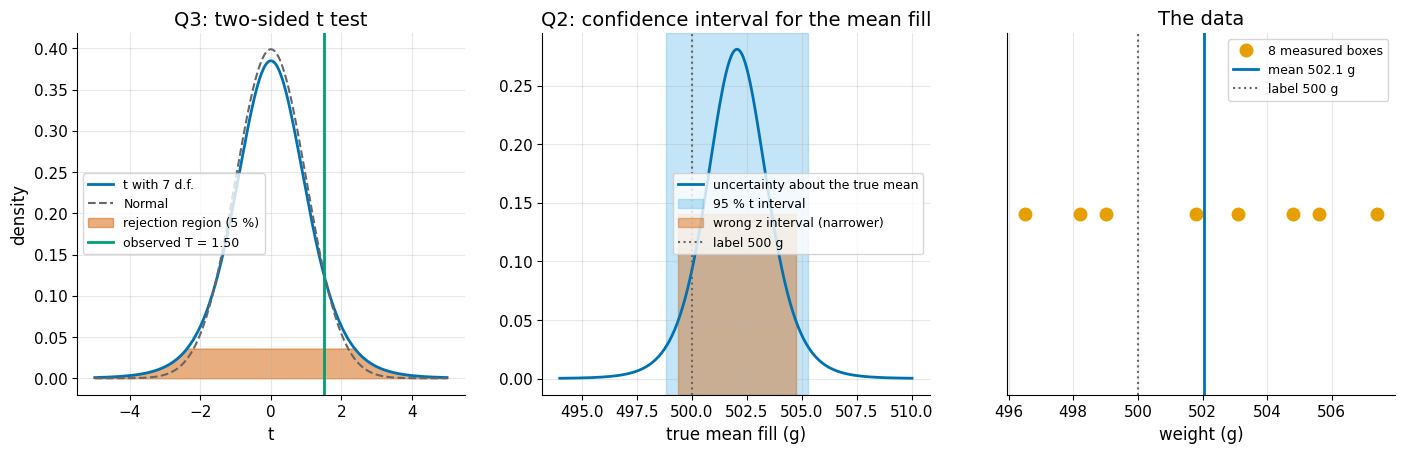

In [19]:
t_axis = np.linspace(-5, 5, 600)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.7))

axes[0].plot(t_axis, t_distribution.pdf(t_axis), color=MAIN, linewidth=2, label="t with 7 d.f.")
axes[0].plot(t_axis, stats.norm.pdf(t_axis), "--", color=NEUTRAL, label="Normal")
rejection = np.abs(t_axis) >= t_critical_table
axes[0].fill_between(t_axis[rejection], t_distribution.pdf(t_axis[rejection]), color=HIGHLIGHT, alpha=0.5, label="rejection region (5 %)")
axes[0].axvline(t_statistic_hand, color=COLORS[2], linewidth=2, label=f"observed T = {t_statistic_hand:.2f}")
axes[0].set_title("Q3: two-sided t test")
axes[0].set_xlabel("t")
axes[0].set_ylabel("density")
axes[0].legend(fontsize=9)

weights_axis = np.linspace(494, 510, 400)
axes[1].plot(weights_axis, stats.t(n - 1, loc=mean_hand, scale=se_hand).pdf(weights_axis), color=MAIN, linewidth=2, label="uncertainty about the true mean")
axes[1].axvspan(*interval_code, color=COLORS[4], alpha=0.35, label="95 % t interval")
axes[1].axvspan(*z_interval, ymax=0.5, color=HIGHLIGHT, alpha=0.4, label="wrong z interval (narrower)")
axes[1].axvline(500, color=NEUTRAL, linestyle=":", label="label 500 g")
axes[1].set_title("Q2: confidence interval for the mean fill")
axes[1].set_xlabel("true mean fill (g)")
axes[1].legend(fontsize=9)

axes[2].plot(weights_array, np.zeros(n), "o", color=SIM, markersize=9, label="8 measured boxes")
axes[2].axvline(mean_hand, color=MAIN, linewidth=2, label=f"mean {mean_hand:.1f} g")
axes[2].axvline(500, color=NEUTRAL, linestyle=":", label="label 500 g")
axes[2].set_yticks([])
axes[2].set_title("The data")
axes[2].set_xlabel("weight (g)")
axes[2].legend(fontsize=9)
plt.show()

### 11.5 Interpretation and decision
- The 8 boxes average **502.05 g** (SD 3.87 g). The **95 % interval for the true mean is 498.8 to 505.3 g**, which comfortably contains the label of 500 g.
- The test statistic (1.50) is below the critical value 2.365, and the p-value (about 0.18) is above 5 %: **there is no evidence the mean differs from 500 g**. With only 8 boxes the test has little power to detect a small overfill.
- A z-interval would have claimed 499.4 to 504.7 g: **too narrow**, because it ignores the uncertainty in the sample SD. With 8 observations this matters.
- **Decision:** the process is acceptable for now; to check for a small overfill of 1 or 2 g, inspect more boxes (a bigger sample gives a narrower interval and a more powerful test).

---
### Example 2: a test for a variance (chi-square)

**Scenario (illustrative).** The filling machine is specified to have an SD of **at most 3 g**. A sample of **20 boxes** gives $s=4.1$ g. Is the machine too variable?

**Hypotheses:** $H_0:\sigma\le3$ vs $H_1:\sigma>3$. **By hand:** $\chi^2=\dfrac{(n-1)s^2}{\sigma_0^2}=\dfrac{19\times16.81}{9}=35.49$ with 19 degrees of freedom. The upper 5 % critical value (table) is 30.14. Since $35.49>30.14$ we **reject** $H_0$. A 95 % confidence interval for $\sigma$ uses the quantiles $\chi^2_{0.025,19}=8.907$ and $\chi^2_{0.975,19}=32.85$: $\sigma\in\Big(\sqrt{\tfrac{19\times16.81}{32.85}},\ \sqrt{\tfrac{19\times16.81}{8.907}}\Big)=(3.12,\ 5.99)$.

In [20]:
n2, s2_observed, sigma_limit = 20, 4.1, 3.0
chi_square_hand = (n2 - 1) * s2_observed**2 / sigma_limit**2
critical_table = 30.14
ci_low_hand = math.sqrt((n2 - 1) * s2_observed**2 / 32.85)
ci_high_hand = math.sqrt((n2 - 1) * s2_observed**2 / 8.907)

chi_distribution = stats.chi2(df=n2 - 1)
assert np.isclose(critical_table, chi_distribution.ppf(0.95), atol=0.01)
assert np.isclose(32.85, chi_distribution.ppf(0.975), atol=0.01) and np.isclose(8.907, chi_distribution.ppf(0.025), atol=0.01)
p_value_variance = chi_distribution.sf(chi_square_hand)
print(f"chi-square = {chi_square_hand:.2f} (critical {critical_table}); p-value = {p_value_variance:.4f}")
print(f"95 % interval for sigma: ({ci_low_hand:.2f}, {ci_high_hand:.2f}) g")

# simulation under H0 (sigma exactly 3): how often is chi-square this large?
simulated_s2 = rng.normal(0, 3.0, size=(300_000, n2)).var(axis=1, ddof=1)
simulated_chi = (n2 - 1) * simulated_s2 / 9
print(f"simulated p-value = {np.mean(simulated_chi >= chi_square_hand):.4f}")
assert abs(np.mean(simulated_chi >= chi_square_hand) - p_value_variance) < 0.002

chi-square = 35.49 (critical 30.14); p-value = 0.0122
95 % interval for sigma: (3.12, 5.99) g


simulated p-value = 0.0123


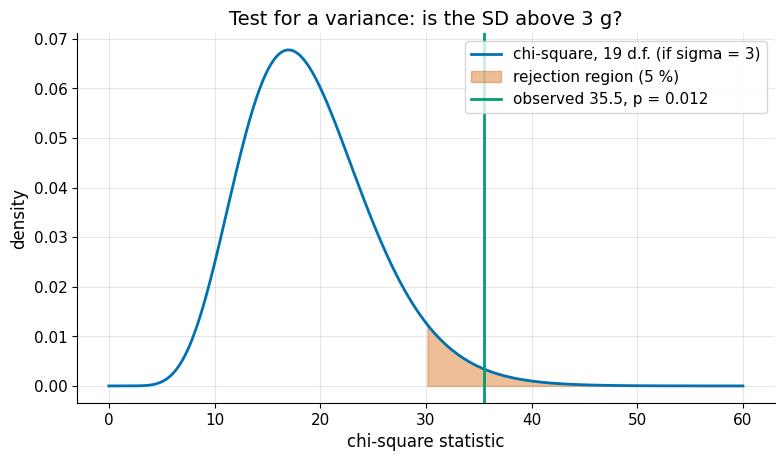

In [21]:
x_axis = np.linspace(0, 60, 600)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(x_axis, chi_distribution.pdf(x_axis), color=MAIN, linewidth=2, label="chi-square, 19 d.f. (if sigma = 3)")
reject = x_axis >= critical_table
ax.fill_between(x_axis[reject], chi_distribution.pdf(x_axis[reject]), color=HIGHLIGHT, alpha=0.4, label="rejection region (5 %)")
ax.axvline(chi_square_hand, color=COLORS[2], linewidth=2, label=f"observed {chi_square_hand:.1f}, p = {p_value_variance:.3f}")
ax.set_title("Test for a variance: is the SD above 3 g?")
ax.set_xlabel("chi-square statistic")
ax.set_ylabel("density")
ax.legend()
plt.show()

**Interpretation.** With 20 boxes and an SD of 4.1 g the statistic (35.5) falls beyond the 5 % critical value 30.1 (p about 0.012): **the machine is more variable than specified**. The plausible range for its true SD is 3.1 to 6.0 g: it is above the 3 g limit even at the low end. **Decision:** service the filler.

---
### Example 3: comparing two variances (F)

**Scenario (illustrative).** Machine A: $n_1=12$ boxes, $s_1=3.2$ g. Machine B: $n_2=15$ boxes, $s_2=5.1$ g. Is machine B more variable?

**By hand.** $F=s_2^2/s_1^2=26.01/10.24=2.540$ with $(14,11)$ degrees of freedom (numerator = B, denominator = A). The 5 % upper critical value from a table is about 2.74. Since $2.54<2.74$, the evidence is **not quite** enough to reject equal variances at 5 % (one-sided).

In [22]:
f_hand = 5.1**2 / 3.2**2
f_distribution = stats.f(14, 11)
critical_f = f_distribution.ppf(0.95)
p_value_f = f_distribution.sf(f_hand)
assert np.isclose(f_hand, 2.540, atol=0.001) and np.isclose(critical_f, 2.74, atol=0.01)
print(f"F = {f_hand:.3f}; 5 % critical value = {critical_f:.3f}; one-sided p-value = {p_value_f:.4f}")

# simulation under H0: equal variances
sim_f = rng.normal(0, 4, size=(300_000, 15)).var(axis=1, ddof=1) / rng.normal(0, 4, size=(300_000, 12)).var(axis=1, ddof=1)
print(f"simulated P(F >= {f_hand:.2f}) = {np.mean(sim_f >= f_hand):.4f}")
assert abs(np.mean(sim_f >= f_hand) - p_value_f) < 0.002

F = 2.540; 5 % critical value = 2.739; one-sided p-value = 0.0635


simulated P(F >= 2.54) = 0.0631


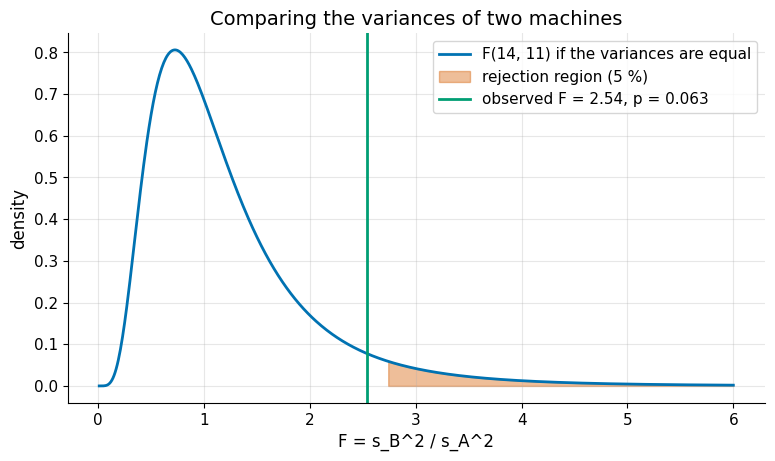

In [23]:
x_axis = np.linspace(0.01, 6, 600)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(x_axis, f_distribution.pdf(x_axis), color=MAIN, linewidth=2, label="F(14, 11) if the variances are equal")
reject = x_axis >= critical_f
ax.fill_between(x_axis[reject], f_distribution.pdf(x_axis[reject]), color=HIGHLIGHT, alpha=0.4, label="rejection region (5 %)")
ax.axvline(f_hand, color=COLORS[2], linewidth=2, label=f"observed F = {f_hand:.2f}, p = {p_value_f:.3f}")
ax.set_title("Comparing the variances of two machines")
ax.set_xlabel("F = s_B^2 / s_A^2")
ax.set_ylabel("density")
ax.legend()
plt.show()

**Interpretation.** Machine B's SD is 60 % larger, but with only 12 and 15 boxes the ratio of variances (2.54) falls just inside what chance can produce (p about 0.06): **suggestive, not conclusive**. **Decision:** weigh a few more boxes from each machine before deciding on maintenance; the F test warns that small samples give noisy variance ratios.

## 12. Where it is used

### Statistics
- **t-tests and confidence intervals** for means with unknown variance (one-sample, two-sample, paired), and for regression coefficients.
- **Chi-square tests:** goodness of fit, independence in contingency tables, variance tests (Module 06).
- **F-tests and ANOVA:** comparing variances, comparing several means, overall regression significance.

### Data science
- **A/B testing** on continuous metrics (revenue per user) uses t-tests (Welch).
- **Model comparison and feature selection:** F-tests for nested models, chi-square tests of independence for categorical features.
- **Quality control:** variance charts and capability studies with small samples.

### ML and AI
- **Heavy-tailed noise models:** Student-t likelihoods for robust regression and Student-t priors; t-SNE uses a t kernel with 1 d.f. to avoid crowding.
- **Gaussian-process and Bayesian regression:** predictive distributions are Student-t when the noise variance is learned.
- **Drift and anomaly tests:** chi-square on feature histograms, F-tests on variances (Module 11).

## 13. Common pitfalls and misconceptions

- **These are exact only for Normal data.** With skewed or heavy-tailed data and small samples the t test can be off; check normality or use a bootstrap or rank test (Module 06).
- **Degrees of freedom:** the sample variance has n - 1 (not n); the two-sample F has (n1 - 1, n2 - 1). Mixing them up changes the critical values.
- **The t is not "the Normal for small samples" because the data are small:** it is wider because s is *estimated*. The effect disappears as n grows.
- **One-sided vs two-sided:** the critical values differ (97.5 % vs 95 % quantile). State the alternative before looking at the data.
- **Chi-square variance tests are very sensitive to non-normality**, much more than t tests for means.
- **F is not symmetric:** put the larger variance on top for a one-sided test, or use both tails.
- **p-value is not the probability that H0 is true.**

## 14. Exercises

1. For a sample of $n=10$ with $\bar x=25$ and $s=4$, compute the 95 % confidence interval for the mean (find the t critical value with code).
2. Compare the 95 % critical value of the t with 5, 10, 30 and 1000 degrees of freedom with 1.96.
3. A sample of 15 values has $s=2.5$. Test $H_0:\sigma=2$ against $H_1:\sigma\ne2$ at the 5 % level (two-sided chi-square test), and give a 90 % confidence interval for $\sigma$.
4. For $\chi^2_{10}$, compute the mean, the variance, and $P(\chi^2_{10}>18.31)$.
5. Show that $t_\nu^2$ has an $F_{1,\nu}$ distribution by checking the 95 % quantiles for $\nu=12$ with code.
6. Two groups have variances 12.5 ($n=10$) and 6.0 ($n=13$). Run an F test of equal variances (two-sided).
7. (Harder) Show that $E[\chi^2_\nu]=\nu$ and $\mathrm{Var}(\chi^2_\nu)=2\nu$ using the Gamma($\nu/2$, 2) moments.
8. (Harder) Simulate the coverage of a nominal 95 % t-interval for $n=10$ when the data are exponential (skewed). How far from 95 % is it?

Solutions are at the end.

## 15. Summary table

| Item | Chi-square | Student's t | F |
|---|---|---|---|
| Parameters | nu (d.f.) | nu (d.f.) | d1, d2 (d.f.) |
| Support | x >= 0 | all reals | x >= 0 |
| Built from | sum of nu squared N(0,1) | Z / sqrt(chi2_nu / nu) | (chi2_d1 / d1) / (chi2_d2 / d2) |
| Mean | nu | 0 (nu > 1) | d2 / (d2 - 2) (d2 > 2) |
| Variance | 2 nu | nu / (nu - 2) (nu > 2) | 2 d2^2 (d1 + d2 - 2) / (d1 (d2 - 2)^2 (d2 - 4)) |
| When to use | variance tests, goodness of fit | mean tests and intervals, unknown sigma, small n | variance ratio, ANOVA, regression F-test |
| `scipy` name | `stats.chi2(df)` | `stats.t(df)` | `stats.f(dfn, dfd)` |

## Solutions

In [24]:
t9 = stats.t.ppf(0.975, 9)
print("1: t critical =", round(t9, 4), " interval =", round(25 - t9 * 4 / np.sqrt(10), 3), round(25 + t9 * 4 / np.sqrt(10), 3))
print("2:", [round(stats.t.ppf(0.975, d), 3) for d in (5, 10, 30, 1000)], " vs", round(stats.norm.ppf(0.975), 3))
chi3 = (15 - 1) * 2.5**2 / 2**2
c3 = stats.chi2(14)
print(f"3: chi-square = {chi3:.2f}, two-sided p = {2 * min(c3.cdf(chi3), c3.sf(chi3)):.4f}; 90% interval for sigma = ({np.sqrt(14 * 6.25 / c3.ppf(0.95)):.3f}, {np.sqrt(14 * 6.25 / c3.ppf(0.05)):.3f})")
print("4: mean", stats.chi2(10).mean(), "var", stats.chi2(10).var(), " P(>18.31) =", round(stats.chi2(10).sf(18.31), 4))
print("5: t_12 97.5%^2 =", round(stats.t.ppf(0.975, 12) ** 2, 4), " F(1, 12) 95% =", round(stats.f.ppf(0.95, 1, 12), 4))
f6 = 12.5 / 6.0
p6 = 2 * min(stats.f(9, 12).cdf(f6), stats.f(9, 12).sf(f6))
print(f"6: F = {f6:.3f}, two-sided p = {p6:.4f}")
exp_data = rng.exponential(1, size=(200_000, 10))
exp_means, exp_se = exp_data.mean(axis=1), exp_data.std(axis=1, ddof=1) / np.sqrt(10)
print("8: coverage of the t-interval for exponential data, n = 10:", round(np.mean(np.abs(exp_means - 1) <= stats.t.ppf(0.975, 9) * exp_se), 4))

1: t critical = 2.2622  interval = 22.139 27.861
2: [np.float64(2.571), np.float64(2.228), np.float64(2.042), np.float64(1.962)]  vs 1.96
3: chi-square = 21.88, two-sided p = 0.1624; 90% interval for sigma = (1.922, 3.649)
4: mean 10.0 var 20.0  P(>18.31) = 0.05
5: t_12 97.5%^2 = 4.7472  F(1, 12) 95% = 4.7472
6: F = 2.083, two-sided p = 0.2354
8: coverage of the t-interval for exponential data, n = 10: 0.9002


**1.** $t_{0.975,9}=2.262$; interval $25\pm2.262\times4/\sqrt{10}=(22.14,\ 27.86)$.

**2.** 2.571, 2.228, 2.042, 1.962 against the Normal's 1.960: the t critical value approaches 1.96 as the degrees of freedom grow.

**3.** $\chi^2=14\times6.25/4=21.88$ with 14 d.f.; the two-sided p-value is about 0.16 (do not reject); a 90 % interval for $\sigma$ is about (1.9, 3.6).

**4.** Mean 10, variance 20, $P(\chi^2_{10}>18.31)\approx0.05$ (18.31 is the 95th percentile).

**5.** $t_{0.975,12}^2=4.747=F_{0.95}(1,12)$, as predicted.

**6.** $F=12.5/6=2.083$ with (9, 12) d.f.; the two-sided p-value is about 0.24: no evidence of unequal variances.

**7.** For Gamma($k=\nu/2$, scale 2): mean $k\theta=\nu$, variance $k\theta^2=2\nu$.

**8.** With skewed data and $n=10$ the coverage is about 90 %: lower than the nominal 95 %. The t procedure is not exact for non-Normal data.